# Thesis Fig. 4 — uncertainty principle, aliasing and sampling density

Reproduction of Tepper (2026), Fig. 4 (thesis PDF p. 57; printed p. 50), panel by panel.

> Left: Gaussian kernels sampled at increasing spacings d with the aliasing error E_alias. Centre: spatial width σ_x
> against spectral spread σ_ξ for several families with the bound σ_xσ_ξ = 1/2. Right: readout against target and
> the design-matrix rasters for each spacing.

**Panels:** A sampled bumps · B uncertainty plane · C readout vs target · D design-matrix rasters (+ r_eff).

**Acceptance (spec 6A.6):** aliasing error matches eq. 6.8 within 5%; σ_xσ_ξ ≥ 1/2 with equality for the Gaussian.

**Parameters [D11]:** `configs/thesis/fig4.yaml`. As in the figure, T = ⌊N/d⌋ observations at c_t = t·d·2π/N; for d
not dividing N they do not tile the ring uniformly. Errors are exact expectations over the target class
(`expected_error`), evaluated on the N-neuron ring.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig4"
cfg = load_config(FIG)
N, decay = cfg["N"], cfg["decay"]
ring = th.Ring(N)
kern = th.Kernel.from_family(cfg["kernel"]["family"], N, **{k: v for k, v in cfg["kernel"].items() if k != "family"})
tc = th.TargetClass.gaussian_psd(N // 2 - 1, beta=cfg["target"]["beta"])
ds = np.array(cfg["spacings"]); Ts = N // ds
pos = [np.arange(T) * d * 2 * np.pi / N for d, T in zip(ds, Ts)]

## Panel A — sampled bumps and E_alias

Bumps x(c_t) at the T sampled positions, plotted against displacement as in the figure. E_alias is reported three
ways, each as a fraction of the total target energy:
eq. 6.8 (target energy at T/2 < |m| ≤ N/2); the exact out-of-band term; and the measured excess error
(E_total − E_total at d = 1).

In [2]:
mult = th.mode_multiplicity(N, tc.psd.size); E_y = float(np.sum(mult * tc.psd))
m = np.arange(tc.psd.size)
E68 = np.array([np.sum((mult * tc.psd)[(m > T / 2) & (m <= N / 2)]) for T in Ts]) / E_y
E_tot = np.array([th.expected_error(kern, tc.psd, None, decay, eval_on="ring", positions=p) for p in pos]) / E_y
E_bias_thesis = np.array([th.error_terms(kern.alloc(), tc.psd, decay, int(T), N).bias for T in Ts]) / E_y
u = np.linspace(-2, 2, 401)
bumps = [np.stack([kern(u - c) for c in (p - np.round(p.mean() / (2 * np.pi / N)) * 0)]) for p in pos]
save_data(FIG, "A_bumps", params={"spacings": ds, "T": Ts},
          u=u, E68=E68, E_total=E_tot, E_excess=E_tot - E_tot[0], E_bias_thesis=E_bias_thesis,
          figure=np.array(cfg["figure_E_alias"]), **{f"bumps_d{d}": b for d, b in zip(ds, bumps)})

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig4/A_bumps.npz')

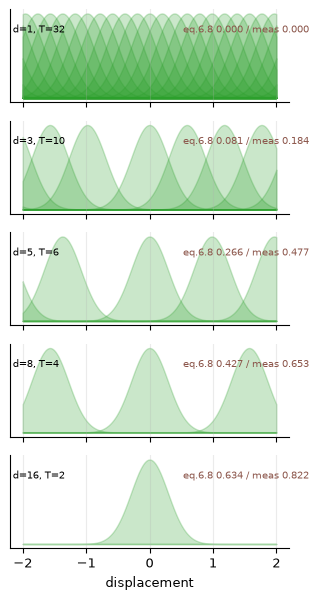

eq. 6.8 E_alias / E_y : [0.     0.0807 0.2664 0.4273 0.6338]
measured excess / E_y : [0.     0.1835 0.4772 0.6529 0.8223]
figure printed values : [0.    0.25  0.447 0.571 0.707]


In [3]:
d = load_data(FIG, "A_bumps")
fig, axs = plt.subplots(5, 1, figsize=(3.6, 7), sharex=True)
for ax, dd, T, e68, ex in zip(axs, ds, Ts, d["E68"], d["E_excess"]):
    b = d[f"bumps_d{dd}"]
    p = np.arange(T) * dd * 2 * np.pi / N
    for c in p:
        cc = (c + np.pi) % (2 * np.pi) - np.pi
        ax.fill_between(d["u"], np.asarray(kern(d["u"] - cc)), alpha=0.25, color="tab:green")
    ax.set_yticks([]); ax.text(0.01, 0.75, f"d={dd}, T={T}", transform=ax.transAxes, fontsize=7)
    ax.text(0.62, 0.75, f"eq.6.8 {e68:.3f} / meas {ex:.3f}", transform=ax.transAxes, fontsize=7, color="tab:brown")
axs[-1].set_xlabel("displacement")
save_figure(FIG, "A_bumps", fig); plt.show()
print("eq. 6.8 E_alias / E_y :", np.round(d["E68"], 4))
print("measured excess / E_y :", np.round(d["E_excess"], 4))
print("figure printed values :", d["figure"])

## Panel B — the uncertainty plane

σ_x by eq. 5.10 and σ_ξ by eq. 5.8, computed on a finer ring (N = 512) for the same families as Fig. 2.

In [4]:
Nu = cfg["up_N"]; labs = list(cfg["up_families"])
sx, sxi, fig_prod = [], [], []
for lab in labs:
    fam, par, fp = cfg["up_families"][lab]
    k = th.Kernel.from_family(fam, Nu, **par)
    sx.append(th.spatial_width(k)); sxi.append(th.spectral_spread(k)); fig_prod.append(fp)
sx, sxi = np.array(sx), np.array(sxi)
save_data(FIG, "B_uncertainty", params={"N": Nu, "families": cfg["up_families"]}, sx=sx, sxi=sxi,
          product=sx * sxi, figure=np.array(fig_prod))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig4/B_uncertainty.npz')

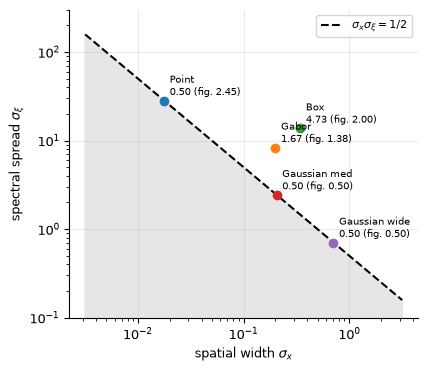

Point          product 0.500   figure 2.45
Gabor          product 1.669   figure 1.38
Box            product 4.734   figure 2.00
Gaussian med   product 0.500   figure 0.50
Gaussian wide  product 0.500   figure 0.50


In [5]:
d = load_data(FIG, "B_uncertainty")
fig, ax = plt.subplots(figsize=(4.5, 4))
xx = np.logspace(-2.5, 0.5, 50)
ax.loglog(xx, 0.5 / xx, "k--", label=r"$\sigma_x\sigma_\xi = 1/2$")
ax.fill_between(xx, 1e-3, 0.5 / xx, color="0.9")
for lab, x, s, p, f in zip(labs, d["sx"], d["sxi"], d["product"], d["figure"]):
    ax.plot(x, s, "o"); ax.annotate(f"{lab}\n{p:.2f} (fig. {f:.2f})", (x, s), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(r"spatial width $\sigma_x$"); ax.set_ylabel(r"spectral spread $\sigma_\xi$"); ax.set_ylim(0.1, 300); ax.legend()
save_figure(FIG, "B_uncertainty", fig); plt.show()
for lab, p, f in zip(labs, d["product"], d["figure"]): print(f"{lab:14s} product {p:.3f}   figure {f:.2f}")

## Panel C — readout against target for each spacing (one target draw)

In [6]:
rng = np.random.default_rng(cfg["seed"])
coeffs = tc.coeffs(rng)
y_ring = tc.evaluate(coeffs, N, ring.positions)
YH = []
for p in pos:
    X = th.activity(kern, p)
    w = th.ridge_readout(X, tc.evaluate(coeffs, N, p), decay)
    YH.append(th.design_matrix(kern, th.Schedule(N, 1)) @ w)
save_data(FIG, "C_readout", c=ring.positions, y=y_ring, YH=np.stack(YH))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig4/C_readout.npz')

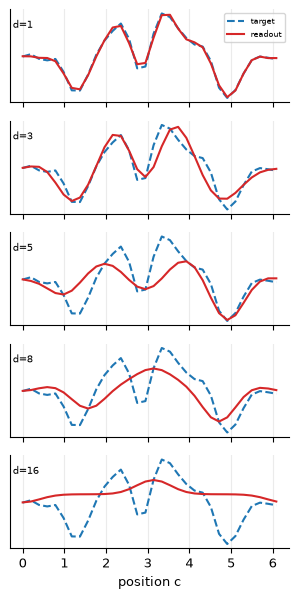

In [7]:
d = load_data(FIG, "C_readout")
fig, axs = plt.subplots(5, 1, figsize=(3.6, 7), sharex=True)
for ax, yh, dd in zip(axs, d["YH"], ds):
    ax.plot(d["c"], d["y"], "--", color="tab:blue", label="target"); ax.plot(d["c"], yh, color="tab:red", label="readout")
    ax.text(0.01, 0.8, f"d={dd}", transform=ax.transAxes, fontsize=7); ax.set_yticks([])
axs[0].legend(fontsize=6); axs[-1].set_xlabel("position c")
save_figure(FIG, "C_readout", fig); plt.show()

## Panel D — design-matrix rasters and effective rank under sampling (eq. 5.4)

In [8]:
Xs = [th.activity(kern, p) for p in pos]
r_eff = np.array([th.sampled_effective_rank(X, cfg["rank_eps"]) for X in Xs])
save_data(FIG, "D_rasters", params={"rank_eps": cfg["rank_eps"]}, r_eff=r_eff, figure=np.array(cfg["figure_r_eff"]),
          **{f"X_d{dd}": X for dd, X in zip(ds, Xs)})

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig4/D_rasters.npz')

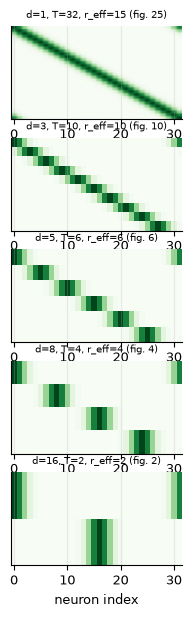

r_eff: [15 10  6  4  2]  figure: [25 10  6  4  2]


In [9]:
d = load_data(FIG, "D_rasters")
fig, axs = plt.subplots(5, 1, figsize=(2.2, 7))
for ax, dd, T, r, f in zip(axs, ds, Ts, d["r_eff"], d["figure"]):
    ax.imshow(d[f"X_d{dd}"], cmap="Greens", aspect="auto"); ax.set_yticks([])
    ax.set_title(f"d={dd}, T={T}, r_eff={r} (fig. {f})", fontsize=7)
axs[-1].set_xlabel("neuron index")
save_figure(FIG, "D_rasters", fig); plt.show()
print("r_eff:", d["r_eff"], " figure:", d["figure"])

## Acceptance

In [10]:
a = load_data(FIG, "A_bumps"); b = load_data(FIG, "B_uncertainty"); dr = load_data(FIG, "D_rasters")
mask = a["E68"] > 0
rel = np.abs(a["E_excess"][mask] - a["E68"][mask]) / a["E68"][mask]
gi = [i for i, l in enumerate(labs) if l.startswith("Gaussian")]
checks = [
    {"item": "aliasing error matches eq. 6.8", "criterion": "|measured excess - eq.6.8| / eq.6.8 < 5% for d > 1",
     "value": rel, "passed": bool(np.all(rel < 0.05))},
    {"item": "uncertainty bound holds", "criterion": "sigma_x sigma_xi >= 1/2 for all families",
     "value": b["product"], "passed": bool(np.all(b["product"] >= 0.5 - 1e-3))},
    {"item": "Gaussian saturates the bound", "criterion": "|product - 1/2| < 1e-2",
     "value": b["product"][gi], "passed": bool(np.all(np.abs(b["product"][gi] - 0.5) < 1e-2))},
    {"item": "r_eff vs figure (reported)", "criterion": "reported only", "value": {"reproduced": dr["r_eff"], "figure": dr["figure"]}, "passed": None},
]
record_checks(FIG, checks)
for c in checks: print(c)

{'item': 'aliasing error matches eq. 6.8', 'criterion': '|measured excess - eq.6.8| / eq.6.8 < 5% for d > 1', 'value': array([1.27346825, 0.79142182, 0.52806487, 0.29733346]), 'passed': False}
{'item': 'uncertainty bound holds', 'criterion': 'sigma_x sigma_xi >= 1/2 for all families', 'value': array([0.5       , 1.6687174 , 4.73396728, 0.5       , 0.49980784]), 'passed': True}
{'item': 'Gaussian saturates the bound', 'criterion': '|product - 1/2| < 1e-2', 'value': array([0.5       , 0.49980784]), 'passed': True}
{'item': 'r_eff vs figure (reported)', 'criterion': 'reported only', 'value': {'reproduced': array([15, 10,  6,  4,  2]), 'figure': array([25, 10,  6,  4,  2])}, 'passed': None}
